# Fraude no Pix: quanto do dinheiro contestado volta?

**Pergunta:** quando uma contestação é aceita, quanto do valor volta pelo MED (Mecanismo Especial de Devolução), e o que impede o restante de voltar?

**Fonte:** API de dados abertos do Banco Central, recurso `EstatisticasFraudesPix`, com dados mensais agregados do sistema, sem identificar instituições ou pessoas.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({
    'figure.figsize': (10, 5.5), 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e6e6', 'axes.axisbelow': True,
})
AZUL, LARANJA, VERDE = '#2f6db3', '#c8553d', '#1f8a70'

## 1. Carga e qualidade dos dados

In [2]:
bruto = pd.read_csv('dados/fraudes_pix.csv')
fraudes = pd.DataFrame({
    'ano_mes': bruto['AnoMes'],
    'ano': bruto['AnoMes'] // 100,
    'contestados': bruto['QtdePixcontestados'],
    'aceitas': bruto['Qtdecontestacoesaceitas'],
    'valor_aceito': bruto['ValorPixcontestadosaceitos'],
    'devolvido': bruto['ValorPixdevolvidosintegralmente'] + bruto['ValorPixdevolvidosparcialmente'],
    'saldo_insuficiente': bruto['ValorPixnaodevolvidossaldoinsuficiente'],
    'residual': bruto['ValorPixresidualnaodevolvido'],
    'conta_encerrada': bruto['Valornaodevolvidoscontaencerrada'],
    'motivos_diversos': bruto['ValorPixnaodevolvidosmotivosdiversos'],
})

partes = ['devolvido', 'saldo_insuficiente', 'residual', 'conta_encerrada', 'motivos_diversos']
diferenca_soma = (fraudes[partes].sum(axis=1) / fraudes['valor_aceito'] - 1).abs().max() * 100
diferenca_pct = ((fraudes['devolvido'] / fraudes['valor_aceito'] * 100) - bruto['PercentualdeDevolucao']).abs().max()

print(f"{len(fraudes)} meses, de {fraudes['ano_mes'].min()} a {fraudes['ano_mes'].max()}, {fraudes.isna().sum().sum()} valores ausentes")
print(f'Maior diferença entre a soma dos destinos e o valor aceito: {diferenca_soma:.3f}%')
print(f'Maior diferença para o percentual publicado: {diferenca_pct:.3f} ponto percentual')

57 meses, de 202201 a 202609, 0 valores ausentes
Maior diferença entre a soma dos destinos e o valor aceito: 0.000%
Maior diferença para o percentual publicado: 0.005 ponto percentual


Os destinos somam exatamente o valor aceito, e o percentual calculado reproduz o publicado pelo Banco Central. Isso dá segurança para usar os componentes separadamente.

## 2. Análise em SQL

As consultas estão em [`sql/consultas.sql`](sql/consultas.sql) e rodam em um SQLite em memória.

In [3]:
conexao = sqlite3.connect(':memory:')
fraudes.to_sql('fraudes', conexao, index=False)

consultas = [c for c in Path('sql/consultas.sql').read_text(encoding='utf-8').split(';') if c.strip()]
por_ano, destinos, movel = [pd.read_sql(c, conexao) for c in consultas]
por_ano

,ano,meses,contestados_mi,aceitacao_pct,valor_aceito_bi,devolucao_pct
0,2022,12,2.1,72.5,3.02,6.3
1,2023,12,4.6,56.5,4.35,9.0
2,2024,12,12.3,40.0,6.69,8.1
3,2025,12,22.2,17.7,7.77,9.0
4,2026,9,27.6,9.2,5.74,13.4


In [4]:
destinos

,destino,valor_bi,participacao_pct
0,Saldo insuficiente,15.16,55.0
1,Residual não devolvido,7.17,26.0
2,Devolvido pelo MED,2.59,9.4
3,Motivos diversos,1.97,7.1
4,Conta encerrada,0.69,2.5


In [5]:
movel.iloc[[11, 23, 35, 47, -1]]

,ano_mes,devolucao_12m_pct
11,202212,6.3
23,202312,9.0
35,202412,8.1
47,202512,9.0
56,202609,12.0


## 3. Para onde vai o valor

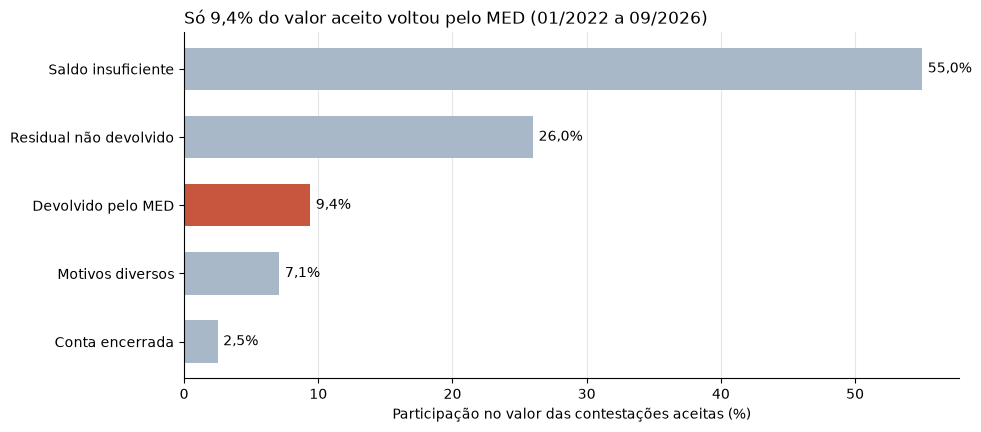

In [6]:
ordem = destinos.sort_values('participacao_pct')
cores = [LARANJA if destino == 'Devolvido pelo MED' else '#a9b8c9' for destino in ordem['destino']]

fig, ax = plt.subplots(figsize=(10, 4.5))
barras = ax.barh(ordem['destino'], ordem['participacao_pct'], color=cores, height=0.62)
ax.bar_label(barras, labels=[f'{p:.1f}%'.replace('.', ',') for p in ordem['participacao_pct']], padding=4)
ax.set_title('Só 9,4% do valor aceito voltou pelo MED (01/2022 a 09/2026)', loc='left')
ax.set_xlabel('Participação no valor das contestações aceitas (%)')
ax.grid(axis='y', visible=False)
fig.savefig('imagens/destino-do-valor.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Mais contestações, menor aceitação

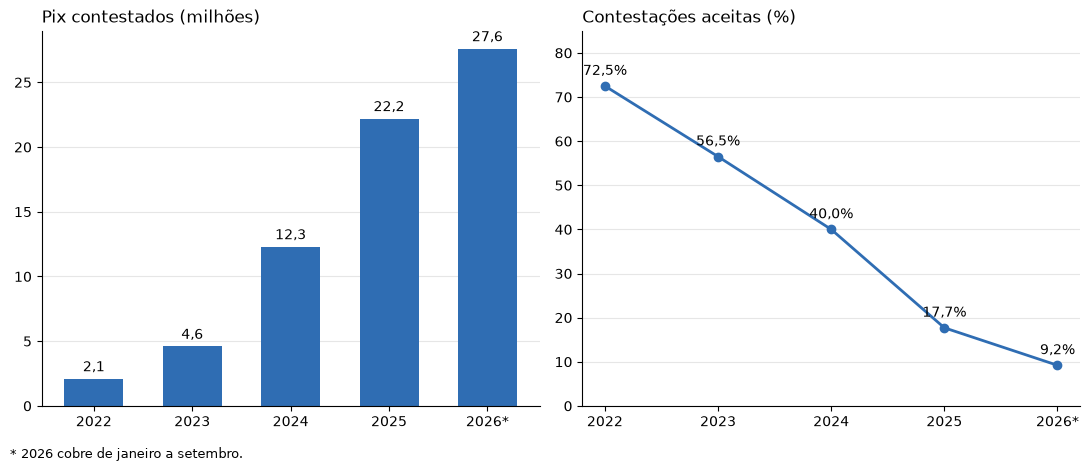

In [7]:
fig, (esquerda, direita) = plt.subplots(1, 2, figsize=(11, 4.5))

rotulos = [f'{ano}*' if meses < 12 else str(ano) for ano, meses in zip(por_ano['ano'], por_ano['meses'])]
barras = esquerda.bar(rotulos, por_ano['contestados_mi'], color=AZUL, width=0.6)
esquerda.bar_label(barras, labels=[f'{v:.1f}'.replace('.', ',') for v in por_ano['contestados_mi']], padding=3)
esquerda.set_title('Pix contestados (milhões)', loc='left')
esquerda.grid(axis='x', visible=False)

direita.plot(rotulos, por_ano['aceitacao_pct'], color=AZUL, linewidth=2, marker='o')
for rotulo, valor in zip(rotulos, por_ano['aceitacao_pct']):
    direita.annotate(f'{valor:.1f}%'.replace('.', ','), (rotulo, valor), textcoords='offset points', xytext=(0, 8), ha='center')
direita.set_ylim(0, 85)
direita.set_title('Contestações aceitas (%)', loc='left')
direita.grid(axis='x', visible=False)

fig.text(0.01, -0.03, '* 2026 cobre de janeiro a setembro.', fontsize=9)
fig.tight_layout()
fig.savefig('imagens/contestacoes.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Conclusões

- **Devolução:** das contestações aceitas, de R$ 27,57 bilhões, R$ 2,59 bilhões (9,4%) voltaram pelo MED.
- **Principal barreira:** em 55,0% do valor, não havia saldo suficiente na conta recebedora. Bloquear o dinheiro cedo parece mais decisivo do que aceitar a contestação depois.
- **Tendência:** a devolução anual subiu de 6,3% em 2022 para 13,4% nos nove primeiros meses de 2026.
- **Volume:** as contestações foram de 2,1 milhões em 2022 para 27,6 milhões em nove meses de 2026, enquanto a aceitação caiu de 72,5% para 9,2%.

**Limites:** a base mostra o que aconteceu, não a causa. A queda na aceitação pode refletir mudanças nas regras, nos canais de contestação ou no perfil dos pedidos, e a base não permite separar esses efeitos. Os bloqueios cautelares devolvidos (R$ 3,95 bilhões) são informados à parte e não entram no percentual, porque a base não diz se há sobreposição com o MED. Os meses mais recentes podem ser revisados.